In [84]:
import pandas as pd #dataAnalysis, Manipulation
import numpy as np #helps in mathematical calculations, numerical python
import seaborn as sns #visualisation
import matplotlib.pyplot as plt #visualisation

In [85]:
#Mercedes C Class Dataset
df = pd.read_csv("/content/cclass.csv")

In [113]:
#Sample data
df.head()

,model,year,price,mileage,engineSize,transmission_Automatic,transmission_Manual,transmission_Other,transmission_Semi-Auto,fuelType_Diesel,fuelType_Hybrid,fuelType_Other,fuelType_Petrol
0,C Class,2020,30495.0,1200.0,2.00,1,0.0,0.0,0,1,0.0,0.0,0
1,C Class,2020,29989.0,1000.0,1.85,1,0.0,0.0,0,0,0.0,0.0,1
2,C Class,2020,37899.0,500.0,2.00,1,0.0,0.0,0,1,0.0,0.0,0
3,C Class,2019,30399.0,5000.0,2.00,1,0.0,0.0,0,1,0.0,0.0,0
4,C Class,2019,29899.0,4500.0,2.00,1,0.0,0.0,0,1,0.0,0.0,0


In [112]:
df.tail()

,model,year,price,mileage,engineSize,transmission_Automatic,transmission_Manual,transmission_Other,transmission_Semi-Auto,fuelType_Diesel,fuelType_Hybrid,fuelType_Other,fuelType_Petrol
3894,C Class,2017,14700.0,31357.0,1.85,0,0.0,0.0,0,1,0.0,0.0,0
3895,C Class,2018,18500.0,28248.0,2.10,1,0.0,0.0,0,1,0.0,0.0,0
3896,C Class,2014,11900.0,48055.0,2.10,0,0.0,0.0,0,1,0.0,0.0,0
3897,C Class,2014,11300.0,49865.0,2.10,1,0.0,0.0,0,1,0.0,0.0,0
3898,C Class,2014,14800.0,55445.0,2.10,1,0.0,0.0,0,1,0.0,0.0,0


In [86]:
#Inspecting the shape, Columns, Rows, Data Types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3899 entries, 0 to 3898
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   model         3899 non-null   object 
 1   year          3899 non-null   int64  
 2   price         3899 non-null   int64  
 3   transmission  3899 non-null   object 
 4   mileage       3899 non-null   int64  
 5   fuelType      3899 non-null   object 
 6   engineSize    3899 non-null   float64
dtypes: float64(1), int64(3), object(3)
memory usage: 213.4+ KB


In [87]:
#Separating numerical and categorical variables
numerical = df.select_dtypes(include="number").columns
categorical = df.select_dtypes(exclude="number").columns

print("Numerical variables:")
print(numerical)

print("Categorical variables:")
print(categorical)

Numerical variables:
Index(['year', 'price', 'mileage', 'engineSize'], dtype='object')
Categorical variables:
Index(['model', 'transmission', 'fuelType'], dtype='object')


In [88]:
#Checking for Duplicates
df.duplicated().sum()

np.int64(102)

In [89]:
#Treating Duplicate values
df.drop_duplicates(inplace=True)

In [90]:
#Confirming dropped Duplicates
df.duplicated().sum()

np.int64(0)

In [91]:
#Checking for missing values
df.isnull().sum()

,0
model,0
year,0
price,0
transmission,0
mileage,0
fuelType,0
engineSize,0


In [92]:
#Identifying objects of object datatype
cols = ["transmission","fuelType"]
for col in cols:
  print(col,df[col].unique())

transmission ['Automatic' 'Semi-Auto' 'Manual' 'Other']
fuelType ['Diesel' 'Petrol' 'Hybrid' 'Other']


In [93]:
#Using correlation concept to identify objects to int data type
df = pd.get_dummies(df,columns=cols,dtype=int)

In [94]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3797 entries, 0 to 3898
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   model                   3797 non-null   object 
 1   year                    3797 non-null   int64  
 2   price                   3797 non-null   int64  
 3   mileage                 3797 non-null   int64  
 4   engineSize              3797 non-null   float64
 5   transmission_Automatic  3797 non-null   int64  
 6   transmission_Manual     3797 non-null   int64  
 7   transmission_Other      3797 non-null   int64  
 8   transmission_Semi-Auto  3797 non-null   int64  
 9   fuelType_Diesel         3797 non-null   int64  
 10  fuelType_Hybrid         3797 non-null   int64  
 11  fuelType_Other          3797 non-null   int64  
 12  fuelType_Petrol         3797 non-null   int64  
dtypes: float64(1), int64(11), object(1)
memory usage: 415.3+ KB


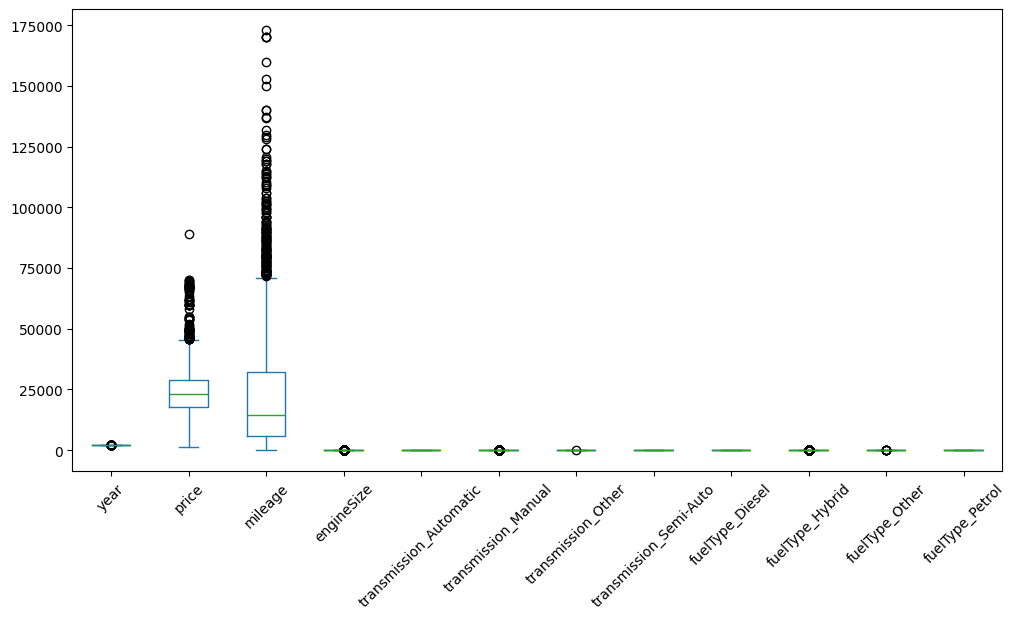

In [95]:
#Identifying Outliers
df.select_dtypes(include = 'number').plot(kind = 'box',figsize = (12,6),rot = 45)
plt.show()

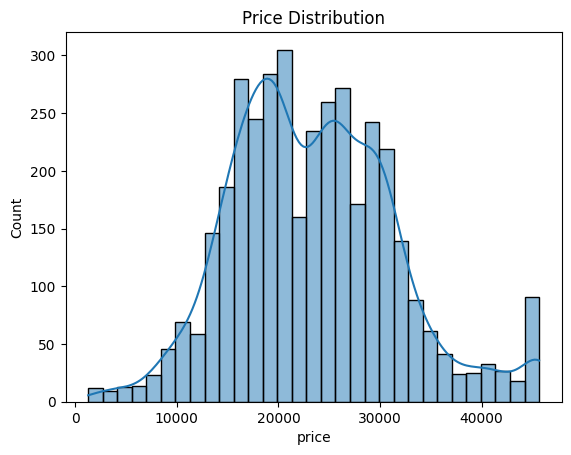

In [97]:
#Univatiate analysis of price using bar graph
sns.histplot(df['price'],kde=True)
plt.title("Price Distribution")
plt.show()

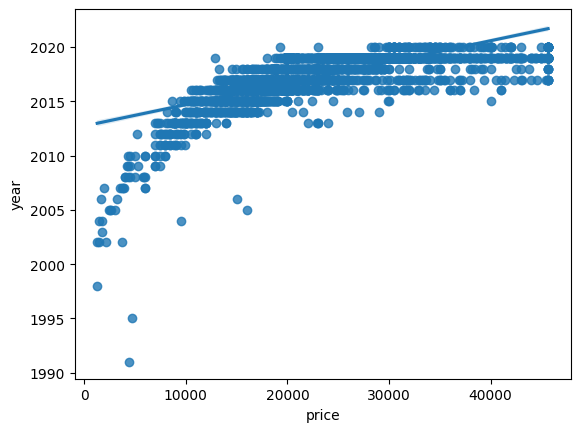

In [110]:
#Bivariate using regplot
sns.regplot(x='price',y='year',data=df)
plt.show()

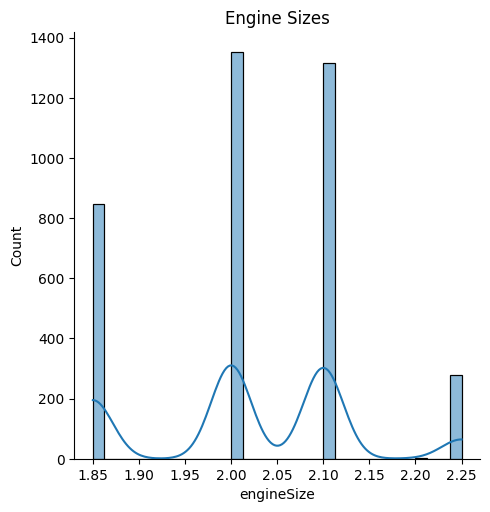

In [99]:

sns.displot(df['engineSize'],kde=True)
plt.title("Engine Sizes")
plt.show()

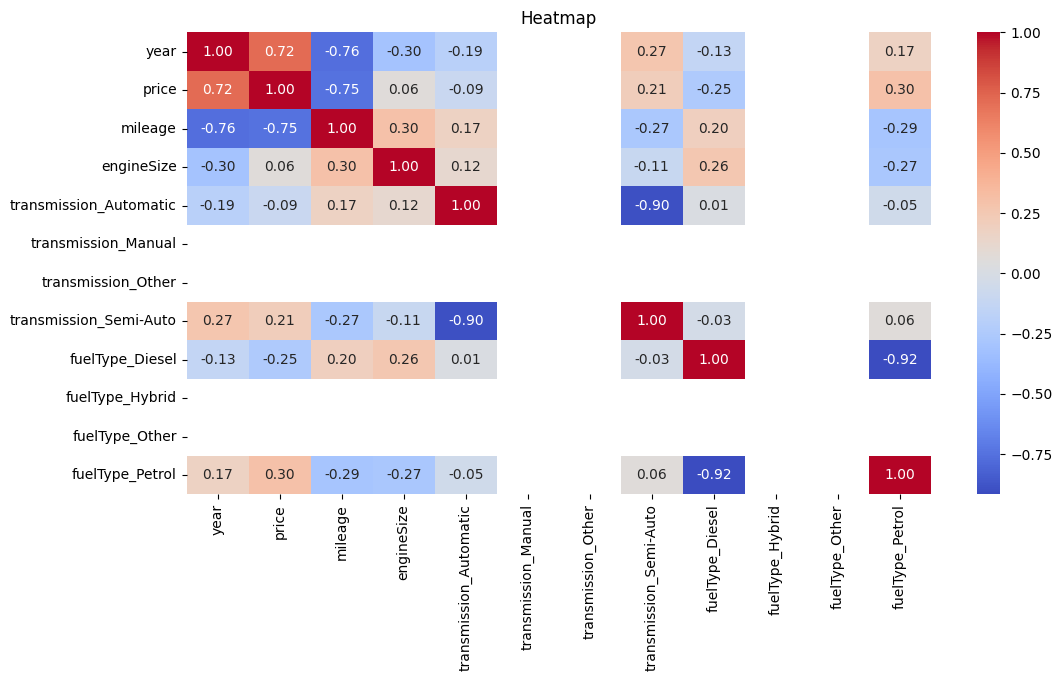

In [100]:
plt.figure(figsize=(12,6))
sns.heatmap(df.select_dtypes(include="number").corr(),annot=True,cmap="coolwarm",fmt=".2f")
plt.title("Heatmap")
plt.show()